In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


products = pd.read_csv('/content/products.csv')
suppliers = pd.read_csv('/content/suppliers.csv')
sales = pd.read_csv('/content/sales.csv')
inventory = pd.read_csv('/content/inventory.csv')
purchases = pd.read_csv('/content/purchases.csv')
expiry = pd.read_csv('/content/expiry_records.csv')

print(products.head())




  Product_ID  Product_Name       Category Supplier_ID  Cost_Price  \
0     PRD001      Milk_001          Dairy      SUP009      136.77   
1     PRD002  Biscuits_002         Snacks      SUP004      213.08   
2     PRD003      Soap_003  Personal Care      SUP019      251.36   
3     PRD004      Milk_004          Dairy      SUP003      122.37   
4     PRD005      Nuts_005         Snacks      SUP020      207.92   

   Selling_Price  Shelf_Life_Days  
0         194.18               15  
1         262.61              180  
2         354.35               60  
3         149.76               15  
4         243.33                7  


In [ ]:
print("PRODUCTS")
print(products.columns)

print("\nSUPPLIERS")
print(suppliers.columns)

print("\nSALES")
print(sales.columns)

print("\nINVENTORY")
print(inventory.columns)

print("\nPURCHASES")
print(purchases.columns)

print("\nEXPIRY")
print(expiry.columns)

PRODUCTS
Index(['Product_ID', 'Product_Name', 'Category', 'Supplier_ID', 'Cost_Price',
       'Selling_Price', 'Shelf_Life_Days'],
      dtype='object')

SUPPLIERS
Index(['Supplier_ID', 'Supplier_Name', 'City', 'Supplier_Rating',
       'Contact_Type'],
      dtype='object')

SALES
Index(['Sale_ID', 'Sale_Date', 'Product_ID', 'Quantity', 'Discount_Percent',
       'Payment_Mode', 'Unit_Price', 'Revenue', 'Total_Cost', 'Profit'],
      dtype='object')

INVENTORY
Index(['Product_ID', 'Stock_Quantity', 'Reorder_Level', 'Maximum_Stock',
       'Last_Restock_Date', 'Snapshot_Date'],
      dtype='object')

PURCHASES
Index(['Purchase_ID', 'Product_ID', 'Supplier_ID', 'Purchase_Date', 'Quantity',
       'Unit_Cost', 'Expected_Delivery_Date', 'Actual_Delivery_Date',
       'Status'],
      dtype='object')

EXPIRY
Index(['Batch_ID', 'Product_ID', 'Received_Date', 'Expiry_Date',
       'Batch_Quantity'],
      dtype='object')


In [ ]:
products.info()
print()
print()
products.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Product_ID       200 non-null    object 
 1   Product_Name     200 non-null    object 
 2   Category         200 non-null    object 
 3   Supplier_ID      200 non-null    object 
 4   Cost_Price       200 non-null    float64
 5   Selling_Price    200 non-null    float64
 6   Shelf_Life_Days  200 non-null    int64  
dtypes: float64(2), int64(1), object(4)
memory usage: 11.1+ KB




,Cost_Price,Selling_Price,Shelf_Life_Days
count,200.000000,200.00000,200.000000
mean,145.983850,191.06445,110.945000
std,84.729226,112.37597,119.603499
min,11.570000,13.17000,7.000000
25%,67.352500,86.86000,15.000000
50%,143.035000,185.07000,60.000000
75%,221.402500,285.98000,180.000000
max,299.140000,429.72000,365.000000


In [ ]:
# Store all six datasets in a dictionary
datasets = {
    'Products': products,
    'Suppliers': suppliers,
    'Sales': sales,
    'Inventory': inventory,
    'Purchases': purchases,
    'Expiry': expiry
}

# Loop through each dataset
for name, df in datasets.items():

    # Display dataset name
    print("\n", name)

    # Count missing values in every column
    print(df.isnull().sum())


 Products
Product_ID         0
Product_Name       0
Category           0
Supplier_ID        0
Cost_Price         0
Selling_Price      0
Shelf_Life_Days    0
dtype: int64

 Suppliers
Supplier_ID        0
Supplier_Name      0
City               0
Supplier_Rating    0
Contact_Type       0
dtype: int64

 Sales
Sale_ID             0
Sale_Date           0
Product_ID          0
Quantity            0
Discount_Percent    0
Payment_Mode        0
Unit_Price          0
Revenue             0
Total_Cost          0
Profit              0
dtype: int64

 Inventory
Product_ID           0
Stock_Quantity       0
Reorder_Level        0
Maximum_Stock        0
Last_Restock_Date    0
Snapshot_Date        0
dtype: int64

 Purchases
Purchase_ID               0
Product_ID                0
Supplier_ID               0
Purchase_Date             0
Quantity                  0
Unit_Cost                 0
Expected_Delivery_Date    0
Actual_Delivery_Date      0
Status                    0
dtype: int64

 Expiry
Batch_ID 

In [ ]:
# Loop through all six datasets
for name, df in datasets.items():

    # Count completely duplicated rows
    duplicates = df.duplicated().sum()
    print(name, "Duplicates:", duplicates)

Products Duplicates: 0
Suppliers Duplicates: 0
Sales Duplicates: 0
Inventory Duplicates: 0
Purchases Duplicates: 0
Expiry Duplicates: 0


In [ ]:
# Removing duplicate records from all datasets

products.drop_duplicates(inplace=True)
suppliers.drop_duplicates(inplace=True)
sales.drop_duplicates(inplace=True)
inventory.drop_duplicates(inplace=True)
purchases.drop_duplicates(inplace=True)
expiry.drop_duplicates(inplace=True)

# Checking duplicates again

for name, df in datasets.items():
    print(name, ":", df.duplicated().sum())

Products : 0
Suppliers : 0
Sales : 0
Inventory : 0
Purchases : 0
Expiry : 0


In [ ]:
# Checking data types of all datasets

for name, df in datasets.items():
    print("\n", name)
    print(df.dtypes)


 Products
Product_ID          object
Product_Name        object
Category            object
Supplier_ID         object
Cost_Price         float64
Selling_Price      float64
Shelf_Life_Days      int64
dtype: object

 Suppliers
Supplier_ID         object
Supplier_Name       object
City                object
Supplier_Rating    float64
Contact_Type        object
dtype: object

 Sales
Sale_ID              object
Sale_Date            object
Product_ID           object
Quantity              int64
Discount_Percent      int64
Payment_Mode         object
Unit_Price          float64
Revenue             float64
Total_Cost          float64
Profit              float64
dtype: object

 Inventory
Product_ID           object
Stock_Quantity        int64
Reorder_Level         int64
Maximum_Stock         int64
Last_Restock_Date    object
Snapshot_Date        object
dtype: object

 Purchases
Purchase_ID                object
Product_ID                 object
Supplier_ID                object
Purchase_Date  

In [ ]:
# Displaying date columns and their current data types

for name, df in datasets.items():
    for col in df.columns:
        if 'date' in col.lower():
            print(name, "-", col, ":", df[col].dtype)

# Converting date columns into datetime format

for name, df in datasets.items():
    for col in df.columns:
        if 'date' in col.lower():
            df[col] = pd.to_datetime(df[col], errors='coerce')

# Checking updated data types

for name, df in datasets.items():
    print("\n", name)
    print(df.dtypes)

Sales - Sale_Date : object
Inventory - Last_Restock_Date : object
Inventory - Snapshot_Date : object
Purchases - Purchase_Date : object
Purchases - Expected_Delivery_Date : object
Purchases - Actual_Delivery_Date : object
Expiry - Received_Date : object
Expiry - Expiry_Date : object

 Products
Product_ID          object
Product_Name        object
Category            object
Supplier_ID         object
Cost_Price         float64
Selling_Price      float64
Shelf_Life_Days      int64
dtype: object

 Suppliers
Supplier_ID         object
Supplier_Name       object
City                object
Supplier_Rating    float64
Contact_Type        object
dtype: object

 Sales
Sale_ID                     object
Sale_Date           datetime64[ns]
Product_ID                  object
Quantity                     int64
Discount_Percent             int64
Payment_Mode                object
Unit_Price                 float64
Revenue                    float64
Total_Cost                 float64
Profit            

In [ ]:
# Checking the total number of products

print("Total Products:", products.shape[0])

# Checking unique product categories

print("Unique Categories:", products.nunique())

Total Products: 200
Unique Categories: Product_ID         200
Product_Name       200
Category             5
Supplier_ID         20
Cost_Price         200
Selling_Price      200
Shelf_Life_Days      7
dtype: int64


In [ ]:
# Checking number of products in each category

products['Category'].value_counts()

,count
Category,
Snacks,45
Dairy,41
Personal Care,41
Beverages,40
Staples,33


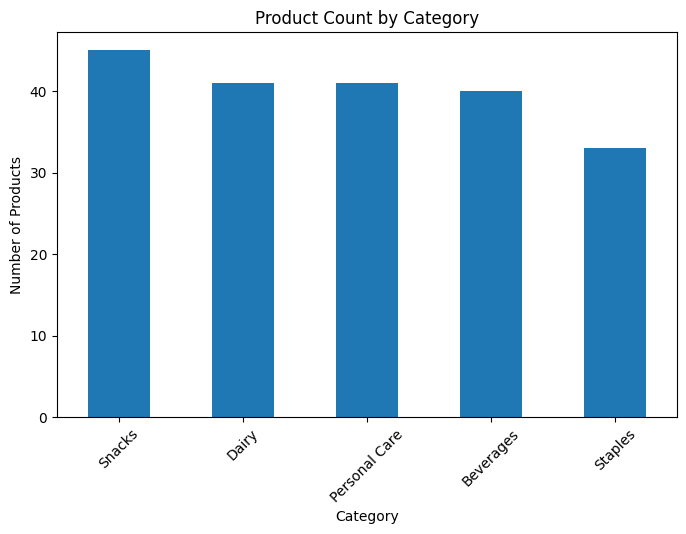

In [ ]:
# Creating a bar chart for product categories

products['Category'].value_counts().plot(kind='bar', figsize=(8,5))

plt.title('Product Count by Category')
plt.xlabel('Category')
plt.ylabel('Number of Products')
plt.xticks(rotation=45)
plt.show()

In [ ]:
# Checking average selling price for each category

products.groupby('Category')['Selling_Price'].mean().round(2)



,Cost_Price
Category,
Beverages,139.08
Dairy,161.09
Personal Care,131.86
Snacks,143.18
Staples,156.95


In [ ]:
# Checking average cost price for each category

products.groupby('Category')['Cost_Price'].mean().round(2)

,Cost_Price
Category,
Beverages,139.08
Dairy,161.09
Personal Care,131.86
Snacks,143.18
Staples,156.95


In [ ]:
# Calculating profit earned on each product

products['Profit'] = products['Selling_Price'] - products['Cost_Price']

# Displaying first 5 products

products[['Product_Name', 'Cost_Price', 'Selling_Price', 'Profit']].head()


,Product_Name,Profit,Profit_Margin
0,Milk_001,57.41,29.565352
1,Biscuits_002,49.53,18.860668
2,Soap_003,102.99,29.064484
3,Milk_004,27.39,18.289263
4,Nuts_005,35.41,14.552254


In [ ]:
# Calculating profit margin percentage

products['Profit_Margin'] = (products['Profit'] / products['Selling_Price']) * 100

# Displaying product-wise profit margin

products[['Product_Name', 'Profit', 'Profit_Margin']].head()

,Product_Name,Profit,Profit_Margin
0,Milk_001,57.41,29.565352
1,Biscuits_002,49.53,18.860668
2,Soap_003,102.99,29.064484
3,Milk_004,27.39,18.289263
4,Nuts_005,35.41,14.552254


In [ ]:
# Checking average profit and profit margin by category

category_profit = products.groupby('Category').agg({
    'Profit': 'mean',
    'Profit_Margin': 'mean'
}).round(2)

category_profit

,Profit,Profit_Margin
Category,,
Beverages,42.03,22.59
Dairy,53.27,24.16
Personal Care,39.10,22.12
Snacks,43.61,23.52
Staples,48.03,22.44


In [ ]:
# Sorting products by profit from highest to lowest

products.sort_values(by='Profit', ascending=False)[
    ['Product_Name', 'Category', 'Profit']
].head(10)

,Product_Name,Category,Profit
182,Chips_183,Snacks,130.58
128,Pulses_129,Staples,120.20
70,Chocolates_071,Snacks,118.51
97,Sugar_098,Staples,114.92
127,Water_128,Beverages,113.30
119,Detergent_120,Personal Care,112.46
195,Soft Drinks_196,Beverages,111.05
80,Paneer_081,Dairy,110.63
55,Butter_056,Dairy,110.49
69,Wheat Flour_070,Staples,104.62


In [ ]:
# Sorting products by profit from lowest to highest

products.sort_values(by='Profit', ascending=True)[
    ['Product_Name', 'Category', 'Profit']
].head(10)

,Product_Name,Category,Profit
191,Toothpaste_192,Personal Care,1.60
99,Cooking Oil_100,Staples,2.42
22,Juice_023,Beverages,2.53
82,Soft Drinks_083,Beverages,2.85
187,Rice_188,Staples,3.81
177,Tea_178,Beverages,3.85
197,Toothpaste_198,Personal Care,4.17
120,Coffee_121,Beverages,4.19
115,Butter_116,Dairy,4.77
14,Chips_015,Snacks,5.25


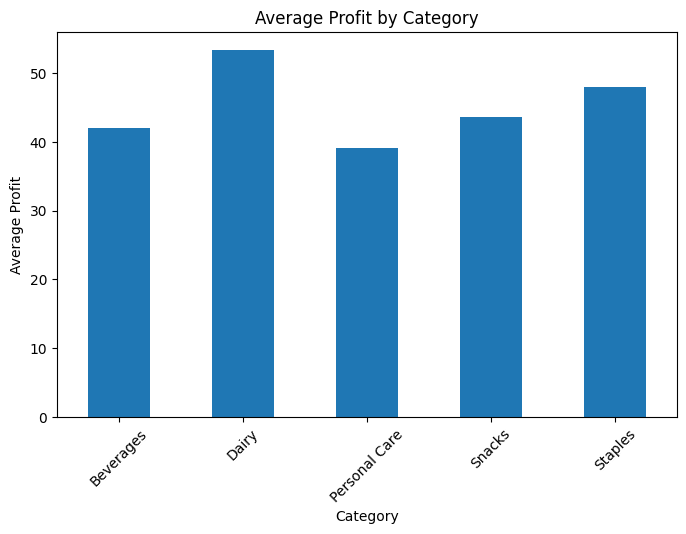

In [ ]:
# Creating a bar chart for average profit by category

category_profit['Profit'].plot(kind='bar', figsize=(8,5))

plt.title('Average Profit by Category')
plt.xlabel('Category')
plt.ylabel('Average Profit')
plt.xticks(rotation=45)
plt.show()

Total Products: 200
Total Categories: 5

Category-wise Product Count:
Category
Snacks           45
Dairy            41
Personal Care    41
Beverages        40
Staples          33
Name: count, dtype: int64

Average Prices by Category:
               Cost_Price  Selling_Price
Category                                
Beverages          139.08         181.11
Dairy              161.09         214.37
Personal Care      131.86         170.96
Snacks             143.18         186.79
Staples            156.95         204.98

Category-wise Profit Analysis:
               Profit  Profit_Margin
Category                            
Beverages       42.03          22.59
Dairy           53.27          24.16
Personal Care   39.10          22.12
Snacks          43.61          23.52
Staples         48.03          22.44

Top 10 Profitable Products:
        Product_Name       Category  Profit
182        Chips_183         Snacks  130.58
128       Pulses_129        Staples  120.20
70    Chocolates_071       

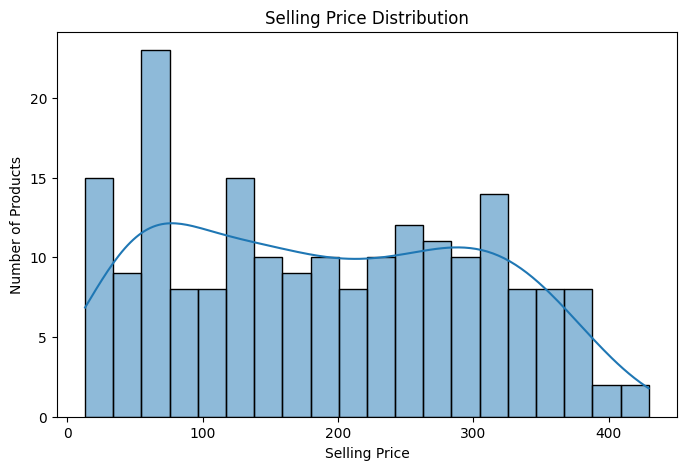

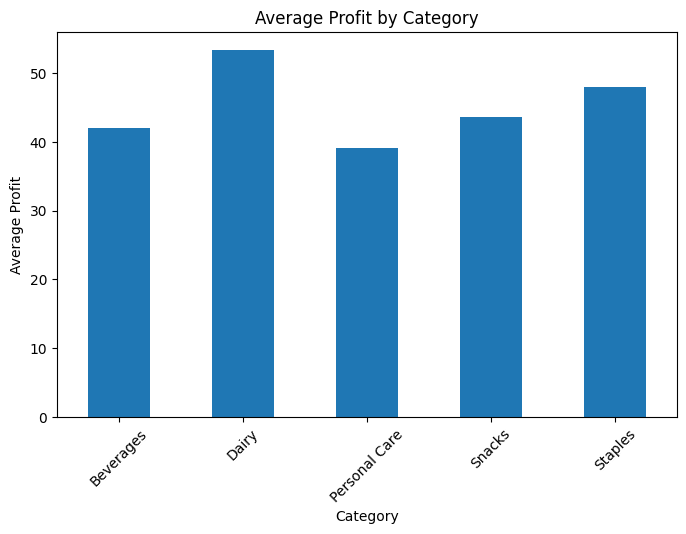

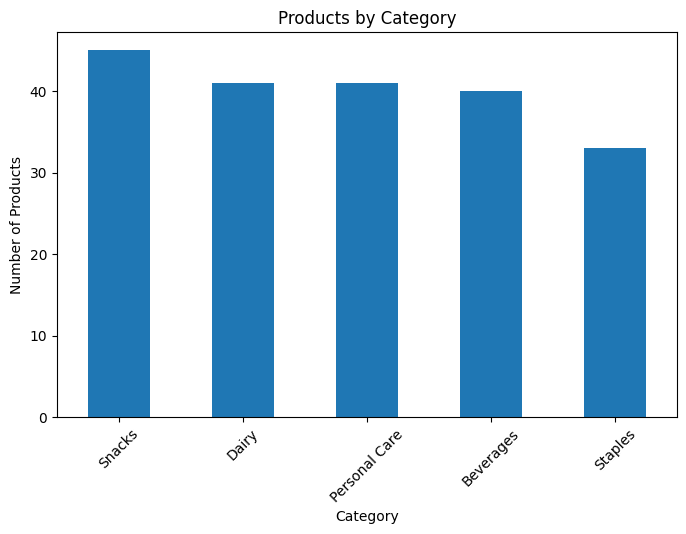

In [ ]:
# 1. Checking total products and categories

print("Total Products:", products.shape[0])
print("Total Categories:", products['Category'].nunique())


# 2. Category-wise product count

print("\nCategory-wise Product Count:")
print(products['Category'].value_counts())


# 3. Category-wise average prices

print("\nAverage Prices by Category:")
print(products.groupby('Category')[['Cost_Price', 'Selling_Price']].mean().round(2))


# 4. Calculating product profit

products['Profit'] = products['Selling_Price'] - products['Cost_Price']


# 5. Calculating profit margin

products['Profit_Margin'] = (products['Profit'] / products['Selling_Price']) * 100


# 6. Category-wise profit analysis

print("\nCategory-wise Profit Analysis:")
print(products.groupby('Category')[['Profit', 'Profit_Margin']].mean().round(2))


# 7. Top 10 most profitable products

print("\nTop 10 Profitable Products:")
print(products.nlargest(10, 'Profit')[['Product_Name', 'Category', 'Profit']])


# 8. Top 10 least profitable products

print("\nTop 10 Least Profitable Products:")
print(products.nsmallest(10, 'Profit')[['Product_Name', 'Category', 'Profit']])


# 9. Products with selling price above 300

print("\nHigh Value Products:")
print(products[products['Selling_Price'] > 300][['Product_Name', 'Category', 'Selling_Price']])


# 10. Overall average selling price

print("\nAverage Selling Price:", round(products['Selling_Price'].mean(), 2))


# 11. Overall average profit

print("Average Profit:", round(products['Profit'].mean(), 2))


# 12. Overall average profit margin

print("Average Profit Margin:", round(products['Profit_Margin'].mean(), 2))


# 13. Selling price distribution

plt.figure(figsize=(8,5))
sns.histplot(products['Selling_Price'], bins=20, kde=True)
plt.title('Selling Price Distribution')
plt.xlabel('Selling Price')
plt.ylabel('Number of Products')
plt.show()


# 14. Category-wise average profit chart

products.groupby('Category')['Profit'].mean().plot(
    kind='bar', figsize=(8,5)
)

plt.title('Average Profit by Category')
plt.xlabel('Category')
plt.ylabel('Average Profit')
plt.xticks(rotation=45)
plt.show()


# 15. Category-wise product count chart

products['Category'].value_counts().plot(
    kind='bar', figsize=(8,5)
)

plt.title('Products by Category')
plt.xlabel('Category')
plt.ylabel('Number of Products')
plt.xticks(rotation=45)
plt.show()

In [ ]:
# ==========================================
# KIRANA STORE INTELLIGENCE
# SALES DATA ANALYSIS
# ==========================================


# 1. Checking basic information

print("Total Sales Records:", sales.shape[0])
print("Total Columns:", sales.shape[1])

print("\nSales Dataset:")
display(sales.head())


# 2. Checking sales dataset information

print("\nSales Information:")
sales.info()


# 3. Checking missing values

print("\nMissing Values:")
print(sales.isnull().sum())


# 4. Checking duplicate records

print("\nDuplicate Records:", sales.duplicated().sum())


# 5. Checking statistical summary

print("\nStatistical Summary:")
display(sales.describe())


# 6. Checking date range

print("\nSales Date Range:")
print("First Sale:", sales.select_dtypes(include='datetime').min())
print("Last Sale:", sales.select_dtypes(include='datetime').max())


# 7. Checking sales columns

print("\nColumn Names:")
print(sales.columns.tolist())


# 8. Checking unique values in each column

print("\nUnique Values:")
print(sales.nunique())


# 9. Checking numerical columns

print("\nNumerical Columns:")
print(sales.select_dtypes(include=np.number).columns.tolist())


# 10. Checking categorical columns

print("\nCategorical Columns:")
print(sales.select_dtypes(include='object').columns.tolist())

Total Sales Records: 10000
Total Columns: 10

Sales Dataset:


,Sale_ID,Sale_Date,Product_ID,Quantity,Discount_Percent,Payment_Mode,Unit_Price,Revenue,Total_Cost,Profit
0,SAL00001,2025-02-01,PRD015,1,15,UPI,24.19,20.56,18.94,1.62
1,SAL00002,2025-11-07,PRD026,4,0,Wallet,74.25,297.00,216.68,80.32
2,SAL00003,2025-06-13,PRD076,6,20,Card,339.92,1631.62,1690.08,-58.46
3,SAL00004,2025-02-26,PRD163,4,20,Wallet,255.13,816.42,803.12,13.30
4,SAL00005,2025-10-24,PRD032,1,0,Card,127.94,127.94,87.10,40.84



Sales Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Sale_ID           10000 non-null  object        
 1   Sale_Date         10000 non-null  datetime64[ns]
 2   Product_ID        10000 non-null  object        
 3   Quantity          10000 non-null  int64         
 4   Discount_Percent  10000 non-null  int64         
 5   Payment_Mode      10000 non-null  object        
 6   Unit_Price        10000 non-null  float64       
 7   Revenue           10000 non-null  float64       
 8   Total_Cost        10000 non-null  float64       
 9   Profit            10000 non-null  float64       
dtypes: datetime64[ns](1), float64(4), int64(2), object(3)
memory usage: 781.4+ KB

Missing Values:
Sale_ID             0
Sale_Date           0
Product_ID          0
Quantity            0
Discount_Percent    0
Payment_Mode  

,Sale_Date,Quantity,Discount_Percent,Unit_Price,Revenue,Total_Cost,Profit
count,10000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,2025-06-30 09:43:37.920000,5.547300,7.189500,190.815197,986.296806,811.314337,174.982469
min,2025-01-01 00:00:00,1.000000,0.000000,13.170000,11.190000,11.570000,-209.920000
25%,2025-04-01 00:00:00,3.000000,0.000000,86.410000,305.385000,250.530000,32.760000
50%,2025-06-29 00:00:00,6.000000,5.000000,187.240000,716.460000,592.380000,99.380000
75%,2025-09-29 00:00:00,8.000000,15.000000,285.770000,1476.720000,1225.620000,251.250000
max,2025-12-31 00:00:00,10.000000,20.000000,429.720000,4142.800000,2991.400000,1202.000000
std,NaN,2.865377,7.498281,111.952795,836.237262,676.711719,205.763282



Sales Date Range:
First Sale: Sale_Date   2025-01-01
dtype: datetime64[ns]
Last Sale: Sale_Date   2025-12-31
dtype: datetime64[ns]

Column Names:
['Sale_ID', 'Sale_Date', 'Product_ID', 'Quantity', 'Discount_Percent', 'Payment_Mode', 'Unit_Price', 'Revenue', 'Total_Cost', 'Profit']

Unique Values:
Sale_ID             10000
Sale_Date             365
Product_ID            200
Quantity               10
Discount_Percent        5
Payment_Mode            4
Unit_Price            200
Revenue              5460
Total_Cost           1978
Profit               5379
dtype: int64

Numerical Columns:
['Quantity', 'Discount_Percent', 'Unit_Price', 'Revenue', 'Total_Cost', 'Profit']

Categorical Columns:
['Sale_ID', 'Product_ID', 'Payment_Mode']


Total Sales Records: 10000
Total Columns: 10

Sales Dataset:


,Sale_ID,Sale_Date,Product_ID,Quantity,Discount_Percent,Payment_Mode,Unit_Price,Revenue,Total_Cost,Profit
0,SAL00001,2025-02-01,PRD015,1,15,UPI,24.19,20.56,18.94,1.62
1,SAL00002,2025-11-07,PRD026,4,0,Wallet,74.25,297.00,216.68,80.32
2,SAL00003,2025-06-13,PRD076,6,20,Card,339.92,1631.62,1690.08,-58.46
3,SAL00004,2025-02-26,PRD163,4,20,Wallet,255.13,816.42,803.12,13.30
4,SAL00005,2025-10-24,PRD032,1,0,Card,127.94,127.94,87.10,40.84



Overall Sales Performance
Total Revenue: 9862968.06
Total Cost: 8113143.37
Total Profit: 1749824.69
Total Units Sold: 55473

Average Sales Metrics
Average Revenue: 986.3
Average Profit: 174.98
Average Quantity: 5.55

Overall Profit Margin: 17.74 %

Payment Mode Distribution
Payment_Mode
Wallet    2518
Cash      2498
UPI       2492
Card      2492
Name: count, dtype: int64

Revenue by Payment Mode
                 Revenue     Profit  Transactions
Payment_Mode                                     
Card          2488242.75  447431.88          2492
Cash          2387463.53  431952.01          2498
UPI           2495581.63  436003.68          2492
Wallet        2491680.15  434437.12          2518

Daily Sales:


,Revenue,Profit,Quantity
Sale_Date,,,
2025-01-01,29716.43,5081.80,148
2025-01-02,27203.68,5676.41,191
2025-01-03,28682.60,4886.40,180
2025-01-04,15515.07,2476.13,80
2025-01-05,20874.64,3284.91,131
2025-01-06,24777.55,4288.29,163
2025-01-07,18696.07,3937.19,141
2025-01-08,23573.98,4027.87,133
2025-01-09,21471.65,3661.85,120



Monthly Sales Performance:


,Revenue,Profit,Quantity,Transactions
Month,,,,
2025-01,748760.22,131012.29,4461,829
2025-02,795050.20,143104.82,4391,779
2025-03,838191.75,140868.38,4817,875
2025-04,840337.63,152182.04,4716,866
2025-05,802151.04,146270.42,4662,832
2025-06,888735.69,161957.10,4779,857
2025-07,844502.10,151964.32,4817,875
2025-08,864733.89,152721.97,4737,841
2025-09,757172.82,134435.86,4313,789


... (3 outputs left out)

,Sale_ID,Sale_Date,Revenue,Profit
8259,SAL08260,2025-07-30,2572.08,-209.92
2552,SAL02553,2025-03-17,2063.59,-201.71
569,SAL00570,2025-02-07,2605.92,-194.68
5186,SAL05187,2025-05-20,2605.92,-194.68
3065,SAL03066,2025-09-25,2179.92,-189.98
5699,SAL05700,2025-06-08,2179.92,-189.98
1614,SAL01615,2025-06-02,2314.87,-188.93
3289,SAL03290,2025-09-04,2314.87,-188.93
105,SAL00106,2025-08-27,1636.96,-176.74
6380,SAL06381,2025-03-16,1636.96,-176.74



Discount Analysis


,Revenue,Profit,Quantity
Discount_Percent,,,
0,1052.29,249.95,5.53
5,1007.54,201.26,5.52
10,1005.08,149.06,5.72
15,873.94,89.12,5.43
20,861.64,38.96,5.57



Average Order Value: 986.3


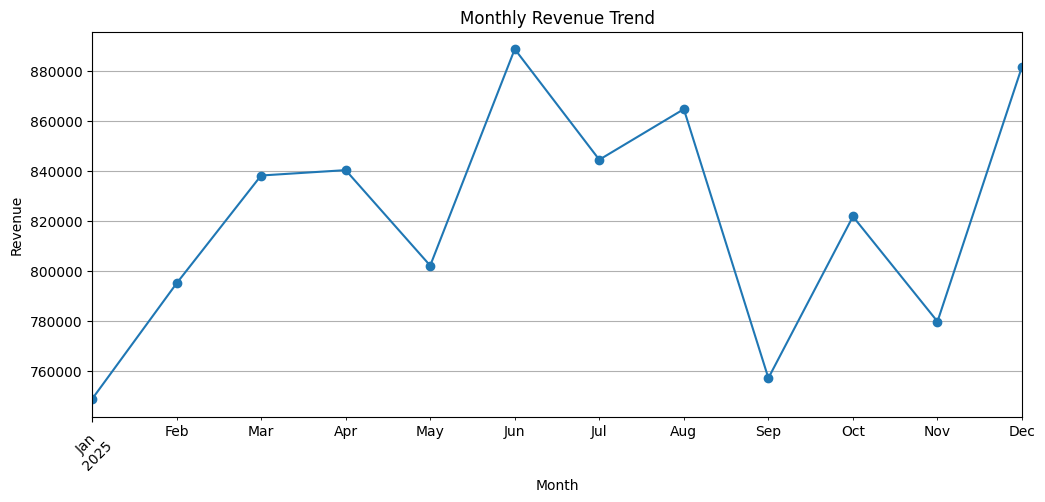

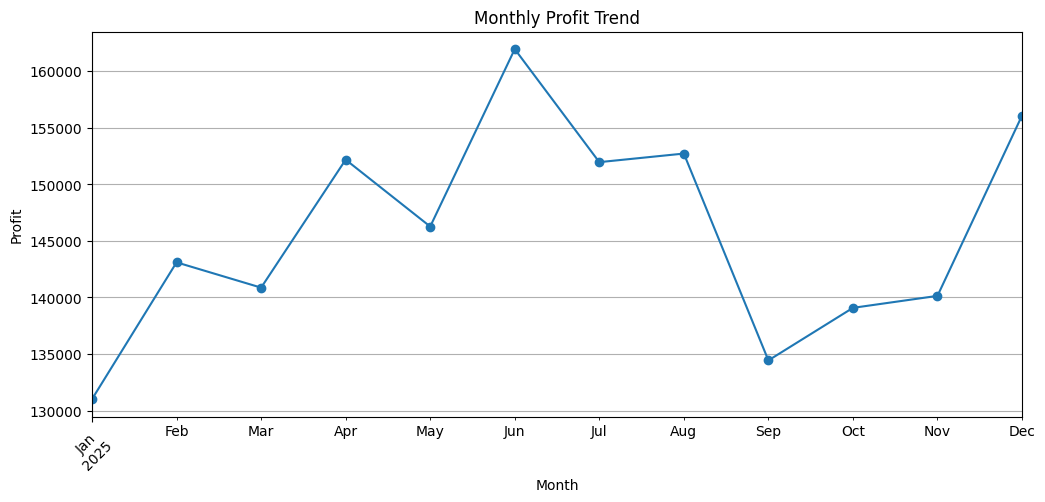

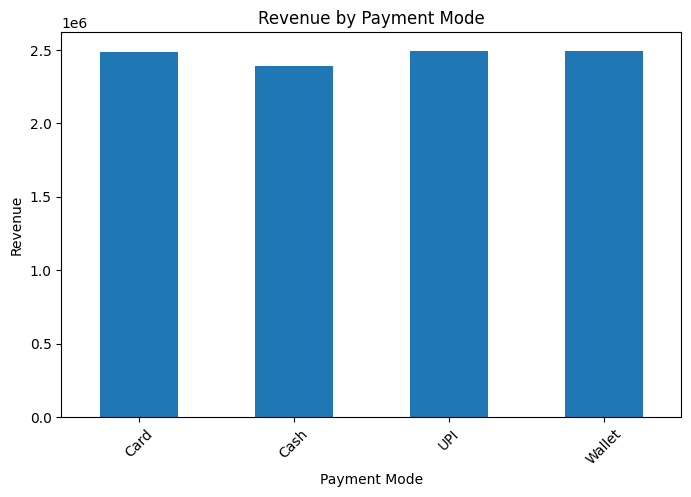

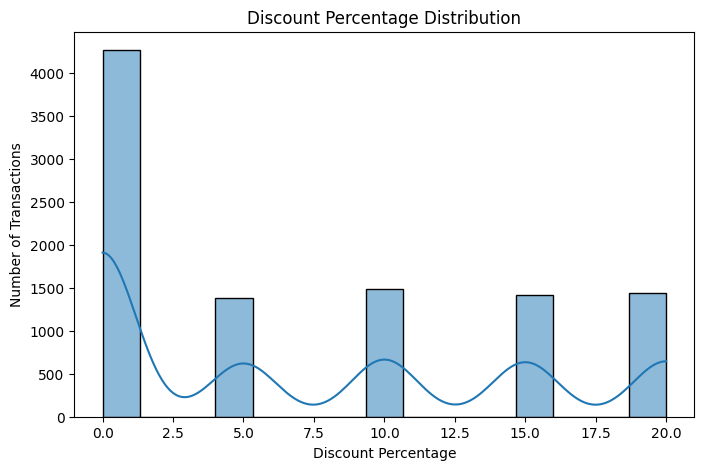

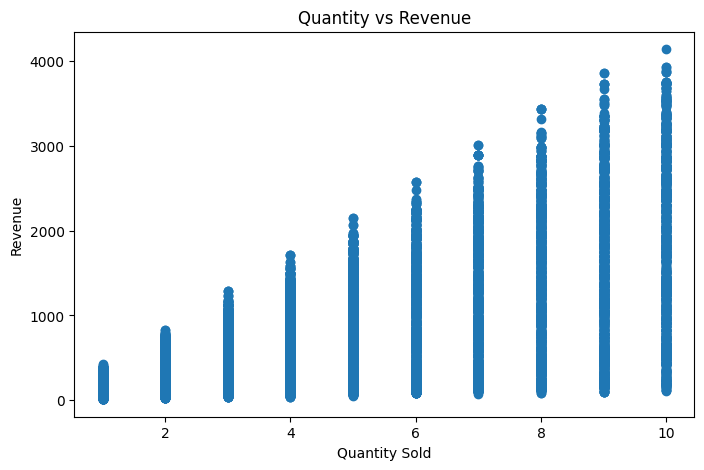

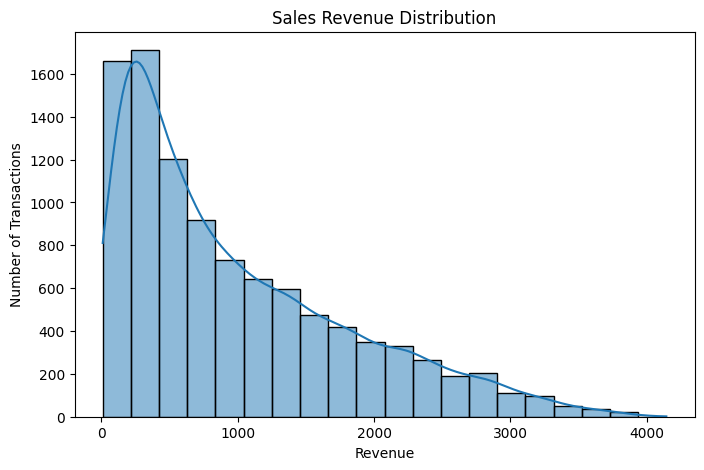


Final Sales Dataset:


,Sale_ID,Sale_Date,Product_ID,Quantity,Discount_Percent,Payment_Mode,Unit_Price,Revenue,Total_Cost,Profit,Month
0,SAL00001,2025-02-01,PRD015,1,15,UPI,24.19,20.56,18.94,1.62,2025-02
1,SAL00002,2025-11-07,PRD026,4,0,Wallet,74.25,297.00,216.68,80.32,2025-11
2,SAL00003,2025-06-13,PRD076,6,20,Card,339.92,1631.62,1690.08,-58.46,2025-06
3,SAL00004,2025-02-26,PRD163,4,20,Wallet,255.13,816.42,803.12,13.30,2025-02
4,SAL00005,2025-10-24,PRD032,1,0,Card,127.94,127.94,87.10,40.84,2025-10
5,SAL00006,2025-09-26,PRD164,10,10,Cash,319.37,2874.33,2345.50,528.83,2025-09
6,SAL00007,2025-01-20,PRD001,4,5,UPI,194.18,737.88,547.08,190.80,2025-01
7,SAL00008,2025-03-12,PRD148,7,0,Card,64.79,453.53,338.17,115.36,2025-03
8,SAL00009,2025-01-06,PRD057,10,0,Wallet,66.86,668.60,506.70,161.90,2025-01
9,SAL00010,2025-04-09,PRD193,6,20,UPI,261.59,1255.63,1114.32,141.31,2025-04


In [ ]:
# ==========================================
# KIRANA STORE INTELLIGENCE
# SALES DATA ANALYSIS
# ==========================================


# 1. Checking basic sales information

print("Total Sales Records:", sales.shape[0])
print("Total Columns:", sales.shape[1])

print("\nSales Dataset:")
display(sales.head())


# 2. Checking total business performance

print("\nOverall Sales Performance")

print("Total Revenue:", round(sales['Revenue'].sum(), 2))
print("Total Cost:", round(sales['Total_Cost'].sum(), 2))
print("Total Profit:", round(sales['Profit'].sum(), 2))
print("Total Units Sold:", sales['Quantity'].sum())


# 3. Calculating average sales metrics

print("\nAverage Sales Metrics")

print("Average Revenue:", round(sales['Revenue'].mean(), 2))
print("Average Profit:", round(sales['Profit'].mean(), 2))
print("Average Quantity:", round(sales['Quantity'].mean(), 2))


# 4. Calculating overall profit margin

total_profit_margin = (
    sales['Profit'].sum() / sales['Revenue'].sum()
) * 100

print("\nOverall Profit Margin:", round(total_profit_margin, 2), "%")


# 5. Checking payment mode distribution

print("\nPayment Mode Distribution")

print(sales['Payment_Mode'].value_counts())


# 6. Analysing revenue by payment mode

print("\nRevenue by Payment Mode")

payment_analysis = sales.groupby('Payment_Mode').agg({
    'Revenue': 'sum',
    'Profit': 'sum',
    'Sale_ID': 'count'
}).rename(columns={'Sale_ID': 'Transactions'})

print(payment_analysis.round(2))


# 7. Analysing daily sales

daily_sales = sales.groupby('Sale_Date').agg({
    'Revenue': 'sum',
    'Profit': 'sum',
    'Quantity': 'sum'
})

print("\nDaily Sales:")
display(daily_sales.head(10))


# 8. Analysing monthly sales

sales['Month'] = sales['Sale_Date'].dt.to_period('M')

monthly_sales = sales.groupby('Month').agg({
    'Revenue': 'sum',
    'Profit': 'sum',
    'Quantity': 'sum',
    'Sale_ID': 'count'
}).rename(columns={'Sale_ID': 'Transactions'})

print("\nMonthly Sales Performance:")
display(monthly_sales)


# 9. Identifying top 10 revenue-generating transactions

print("\nTop 10 Sales Transactions")

top_sales = sales.nlargest(10, 'Revenue')

display(top_sales[
    ['Sale_ID', 'Sale_Date', 'Quantity', 'Revenue', 'Profit']
])


# 10. Identifying least profitable transactions

print("\n10 Least Profitable Transactions")

least_sales = sales.nsmallest(10, 'Profit')

display(least_sales[
    ['Sale_ID', 'Sale_Date', 'Revenue', 'Profit']
])


# 11. Analysing discount impact

print("\nDiscount Analysis")

discount_analysis = sales.groupby('Discount_Percent').agg({
    'Revenue': 'mean',
    'Profit': 'mean',
    'Quantity': 'mean'
})

display(discount_analysis.round(2))


# 12. Calculating average order value

average_order_value = sales['Revenue'].sum() / sales['Sale_ID'].nunique()

print("\nAverage Order Value:", round(average_order_value, 2))


# 13. Monthly revenue trend

plt.figure(figsize=(12, 5))

monthly_sales['Revenue'].plot(kind='line', marker='o')

plt.title('Monthly Revenue Trend')
plt.xlabel('Month')
plt.ylabel('Revenue')
plt.xticks(rotation=45)
plt.grid()
plt.show()


# 14. Monthly profit trend

plt.figure(figsize=(12, 5))

monthly_sales['Profit'].plot(kind='line', marker='o')

plt.title('Monthly Profit Trend')
plt.xlabel('Month')
plt.ylabel('Profit')
plt.xticks(rotation=45)
plt.grid()
plt.show()


# 15. Payment mode revenue comparison

plt.figure(figsize=(8, 5))

payment_analysis['Revenue'].plot(kind='bar')

plt.title('Revenue by Payment Mode')
plt.xlabel('Payment Mode')
plt.ylabel('Revenue')
plt.xticks(rotation=45)
plt.show()


# 16. Discount distribution

plt.figure(figsize=(8, 5))

sns.histplot(sales['Discount_Percent'], bins=15, kde=True)

plt.title('Discount Percentage Distribution')
plt.xlabel('Discount Percentage')
plt.ylabel('Number of Transactions')
plt.show()


# 17. Quantity vs Revenue

plt.figure(figsize=(8, 5))

plt.scatter(sales['Quantity'], sales['Revenue'])

plt.title('Quantity vs Revenue')
plt.xlabel('Quantity Sold')
plt.ylabel('Revenue')
plt.show()


# 18. Revenue distribution

plt.figure(figsize=(8, 5))

sns.histplot(sales['Revenue'], bins=20, kde=True)

plt.title('Sales Revenue Distribution')
plt.xlabel('Revenue')
plt.ylabel('Number of Transactions')
plt.show()


# 19. Checking final sales dataset

print("\nFinal Sales Dataset:")
display(sales.head(10))

Total Records: 10000


,Sale_ID,Sale_Date,Product_ID,Quantity,Discount_Percent,Payment_Mode,Unit_Price,Revenue,Total_Cost,Profit_x,Month,Product_Name,Category,Supplier_ID,Cost_Price,Selling_Price,Shelf_Life_Days,Profit_y,Profit_Margin
0,SAL00001,2025-02-01,PRD015,1,15,UPI,24.19,20.56,18.94,1.62,2025-02,Chips_015,Snacks,SUP002,18.94,24.19,180,5.25,21.703183
1,SAL00002,2025-11-07,PRD026,4,0,Wallet,74.25,297.00,216.68,80.32,2025-11,Soft Drinks_026,Beverages,SUP016,54.17,74.25,60,20.08,27.043771
2,SAL00003,2025-06-13,PRD076,6,20,Card,339.92,1631.62,1690.08,-58.46,2025-06,Paneer_076,Dairy,SUP016,281.68,339.92,90,58.24,17.133443
3,SAL00004,2025-02-26,PRD163,4,20,Wallet,255.13,816.42,803.12,13.30,2025-02,Namkeen_163,Snacks,SUP014,200.78,255.13,60,54.35,21.302865
4,SAL00005,2025-10-24,PRD032,1,0,Card,127.94,127.94,87.10,40.84,2025-10,Cheese_032,Dairy,SUP006,87.10,127.94,365,40.84,31.921213



Top 10 Revenue Generating Products:


,Product_ID,Product_Name,Category,Quantity,Revenue,Total_Cost,Total_Profit
2,PRD003,Soap_003,Personal Care,397,130347.66,99789.92,30557.74
128,PRD129,Pulses_129,Staples,326,125236.83,95870.08,29366.75
140,PRD141,Shampoo_141,Personal Care,371,123408.85,102299.54,21109.31
69,PRD070,Wheat Flour_070,Staples,342,119651.12,91857.78,27793.34
7,PRD008,Cheese_008,Dairy,402,110264.40,86229.00,24035.40
195,PRD196,Soft Drinks_196,Beverages,302,109737.95,84276.12,25461.83
127,PRD128,Water_128,Beverages,312,108781.48,79447.68,29333.80
158,PRD159,Paneer_159,Dairy,354,107922.05,81965.16,25956.89
72,PRD073,Detergent_073,Personal Care,352,103985.98,82325.76,21660.22
80,PRD081,Paneer_081,Dairy,321,103045.31,75579.45,27465.86



Top 10 Profitable Products:


,Product_ID,Product_Name,Category,Quantity,Revenue,Total_Cost,Total_Profit
2,PRD003,Soap_003,Personal Care,397,130347.66,99789.92,30557.74
128,PRD129,Pulses_129,Staples,326,125236.83,95870.08,29366.75
127,PRD128,Water_128,Beverages,312,108781.48,79447.68,29333.80
69,PRD070,Wheat Flour_070,Staples,342,119651.12,91857.78,27793.34
80,PRD081,Paneer_081,Dairy,321,103045.31,75579.45,27465.86
158,PRD159,Paneer_159,Dairy,354,107922.05,81965.16,25956.89
195,PRD196,Soft Drinks_196,Beverages,302,109737.95,84276.12,25461.83
55,PRD056,Butter_056,Dairy,278,94816.96,69394.36,25422.60
182,PRD183,Chips_183,Snacks,248,98835.60,74186.72,24648.88
7,PRD008,Cheese_008,Dairy,402,110264.40,86229.00,24035.40



Category-wise Sales Performance:


,Quantity,Revenue,Total_Cost,Total_Profit
Category,,,,
Beverages,11055,1857078.99,1535140.53,321938.46
Dairy,11288,2262803.89,1818901.02,443902.87
Personal Care,11250,1801015.87,1496855.91,304159.96
Snacks,12704,2209721.49,1830153.39,379568.10
Staples,9176,1732347.82,1432092.52,300255.30


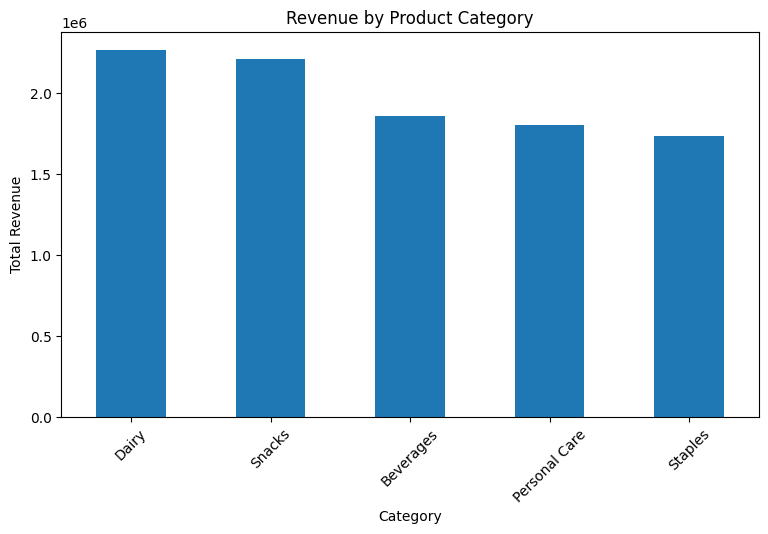

<Figure size 1000x500 with 0 Axes>

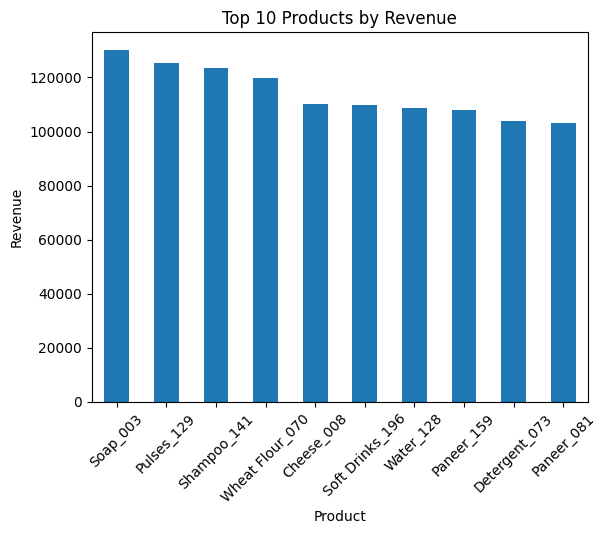


Final Product Sales Analysis:


,Product_ID,Product_Name,Category,Quantity,Revenue,Total_Cost,Total_Profit
2,PRD003,Soap_003,Personal Care,397,130347.66,99789.92,30557.74
128,PRD129,Pulses_129,Staples,326,125236.83,95870.08,29366.75
140,PRD141,Shampoo_141,Personal Care,371,123408.85,102299.54,21109.31
69,PRD070,Wheat Flour_070,Staples,342,119651.12,91857.78,27793.34
7,PRD008,Cheese_008,Dairy,402,110264.40,86229.00,24035.40
195,PRD196,Soft Drinks_196,Beverages,302,109737.95,84276.12,25461.83
127,PRD128,Water_128,Beverages,312,108781.48,79447.68,29333.80
158,PRD159,Paneer_159,Dairy,354,107922.05,81965.16,25956.89
72,PRD073,Detergent_073,Personal Care,352,103985.98,82325.76,21660.22
80,PRD081,Paneer_081,Dairy,321,103045.31,75579.45,27465.86


In [ ]:
# ==========================================
# PRODUCT-WISE SALES ANALYSIS
# ==========================================


# 1. Merging sales and products datasets

product_sales = pd.merge(
    sales,
    products,
    on='Product_ID',
    how='left'
)


# 2. Checking merged dataset

print("Total Records:", product_sales.shape[0])

display(product_sales.head())


# 3. Product-wise sales performance

product_performance = product_sales.groupby(
    ['Product_ID', 'Product_Name', 'Category']
).agg({
    'Quantity': 'sum',
    'Revenue': 'sum',
    'Total_Cost': 'sum',
    'Profit_x': 'sum'
}).reset_index()


# 4. Renaming profit column

product_performance.rename(
    columns={'Profit_x': 'Total_Profit'},
    inplace=True
)


# 5. Sorting products by revenue

product_performance = product_performance.sort_values(
    by='Revenue',
    ascending=False
)

print("\nTop 10 Revenue Generating Products:")

display(product_performance.head(10))


# 6. Finding top 10 profitable products

print("\nTop 10 Profitable Products:")

display(
    product_performance.nlargest(10, 'Total_Profit')
)


# 7. Category-wise sales performance

category_sales = product_sales.groupby('Category').agg({
    'Quantity': 'sum',
    'Revenue': 'sum',
    'Total_Cost': 'sum',
    'Profit_x': 'sum'
}).round(2)

category_sales.rename(
    columns={'Profit_x': 'Total_Profit'},
    inplace=True
)

print("\nCategory-wise Sales Performance:")

display(category_sales)


# 8. Category-wise revenue chart

plt.figure(figsize=(9, 5))

category_sales['Revenue'].sort_values(ascending=False).plot(
    kind='bar'
)

plt.title('Revenue by Product Category')
plt.xlabel('Category')
plt.ylabel('Total Revenue')
plt.xticks(rotation=45)
plt.show()


# 9. Top 10 products by revenue chart

plt.figure(figsize=(10, 5))

product_performance.head(10).plot(
    x='Product_Name',
    y='Revenue',
    kind='bar',
    legend=False
)

plt.title('Top 10 Products by Revenue')
plt.xlabel('Product')
plt.ylabel('Revenue')
plt.xticks(rotation=45)
plt.show()


# 10. Final product sales performance

print("\nFinal Product Sales Analysis:")

display(product_performance.head(20))

Total Purchase Records: 1000
Total Columns: 9


,Purchase_ID,Product_ID,Supplier_ID,Purchase_Date,Quantity,Unit_Cost,Expected_Delivery_Date,Actual_Delivery_Date,Status
0,PUR0001,PRD073,SUP018,2025-09-09,193,293.99,2025-09-13,2025-09-18,Delayed
1,PUR0002,PRD143,SUP016,2025-08-10,142,155.64,2025-08-16,2025-08-15,On Time
2,PUR0003,PRD077,SUP002,2025-08-31,114,22.45,2025-09-06,2025-09-04,On Time
3,PUR0004,PRD147,SUP017,2025-09-18,156,77.95,2025-09-24,2025-09-24,On Time
4,PUR0005,PRD119,SUP018,2025-03-18,64,71.68,2025-03-20,2025-03-18,On Time



Purchase Summary:


,Purchase_Date,Quantity,Unit_Cost,Expected_Delivery_Date,Actual_Delivery_Date
count,1000,1000.000000,1000.000000,1000,1000
mean,2025-06-21 22:00:28.800000,109.017000,158.167140,2025-06-25 23:49:55.200000,2025-06-27 03:01:26.399999744
min,2025-01-01 00:00:00,20.000000,10.160000,2025-01-04 00:00:00,2025-01-04 00:00:00
25%,2025-03-30 00:00:00,65.000000,85.307500,2025-04-03 00:00:00,2025-04-04 00:00:00
50%,2025-06-17 00:00:00,107.000000,158.185000,2025-06-22 00:00:00,2025-06-23 00:00:00
75%,2025-09-16 06:00:00,153.000000,236.432500,2025-09-21 00:00:00,2025-09-21 00:00:00
max,2025-12-15 00:00:00,200.000000,299.280000,2025-12-20 00:00:00,2025-12-24 00:00:00
std,NaN,51.047591,84.289214,NaN,NaN



Total Purchase Quantity: 109017
Total Purchase Amount: 17039969.57

Purchase Status:
Status
Delayed    584
On Time    416
Name: count, dtype: int64

Supplier-wise Purchase Analysis:


,Total_Orders,Total_Quantity,Purchase_Amount
Supplier_ID,,,
SUP018,62,7005,1193598.14
SUP004,59,6471,1112148.52
SUP013,59,6060,944648.52
SUP008,52,5716,937222.41
SUP006,56,6141,934657.34
SUP012,47,5802,880756.72
SUP007,52,5670,874207.76
SUP011,56,5488,861557.78
SUP005,45,5059,855232.97


... (4 outputs left out)


Delayed Purchases:


,Purchase_ID,Product_ID,Supplier_ID,Purchase_Date,Quantity,Unit_Cost,Expected_Delivery_Date,Actual_Delivery_Date,Status,Purchase_Amount,Delivery_Days
0,PUR0001,PRD073,SUP018,2025-09-09,193,293.99,2025-09-13,2025-09-18,Delayed,56740.07,5
5,PUR0006,PRD097,SUP011,2025-10-11,101,281.23,2025-10-14,2025-10-17,Delayed,28404.23,3
6,PUR0007,PRD112,SUP010,2025-09-07,24,131.55,2025-09-13,2025-09-18,Delayed,3157.20,5
7,PUR0008,PRD181,SUP020,2025-04-18,154,284.83,2025-04-23,2025-04-26,Delayed,43863.82,3
8,PUR0009,PRD136,SUP018,2025-06-25,78,259.28,2025-06-28,2025-07-01,Delayed,20223.84,3
...,...,...,...,...,...,...,...,...,...,...,...
994,PUR0995,PRD100,SUP017,2025-02-18,77,253.77,2025-02-22,2025-02-24,Delayed,19540.29,2
995,PUR0996,PRD139,SUP015,2025-06-26,41,127.80,2025-07-02,2025-07-03,Delayed,5239.80,1
996,PUR0997,PRD152,SUP013,2025-09-10,105,196.49,2025-09-13,2025-09-16,Delayed,20631.45,3
997,PUR0998,PRD071,SUP001,2025-07-08,50,170.19,2025-07-11,2025-07-12,Delayed,8509.50,1



Delayed Orders: 584
On-time or Early Orders: 416

Monthly Purchase Analysis:


,Purchase_Amount,Quantity,Total_Orders
Month,,,
2025-01,1308457.06,8097,74
2025-02,1431940.91,9577,82
2025-03,1590862.41,10349,97
2025-04,1794592.71,11263,109
2025-05,1369035.05,8376,82
2025-06,1797246.24,11371,99
2025-07,1194142.26,7479,71
2025-08,1339505.66,9189,91
2025-09,1709205.29,10220,88


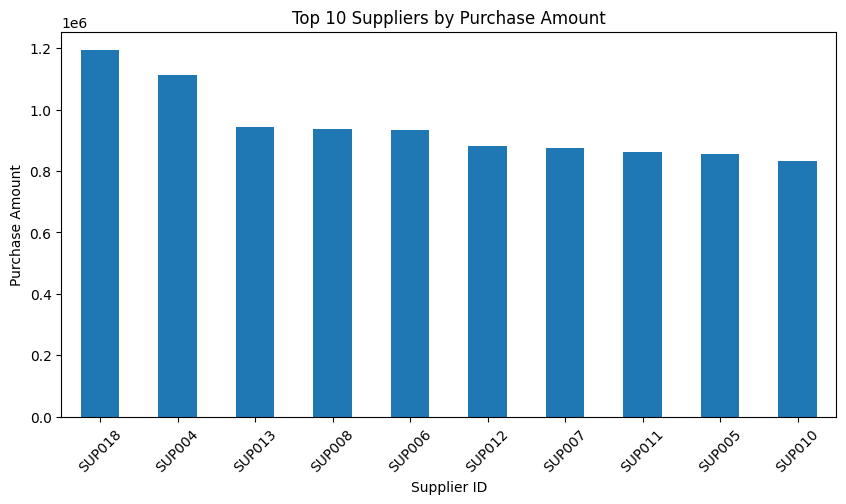

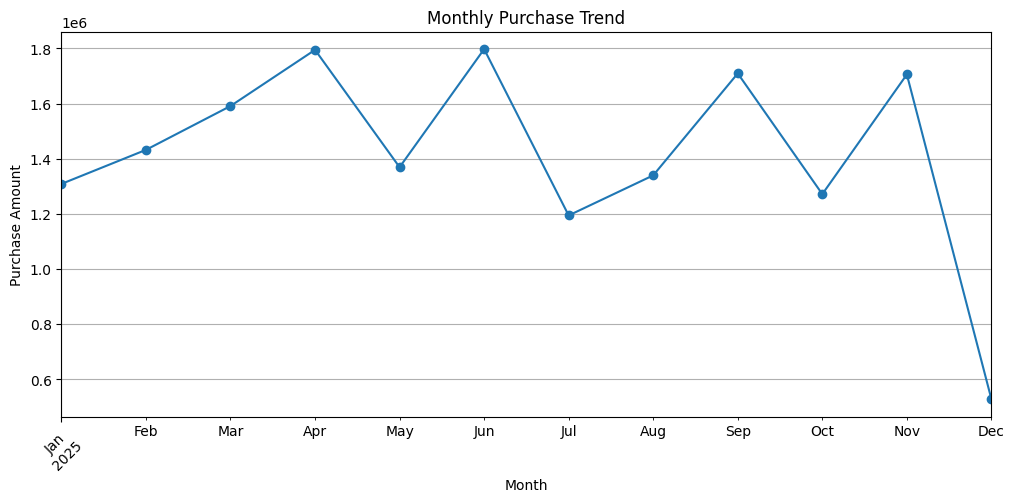

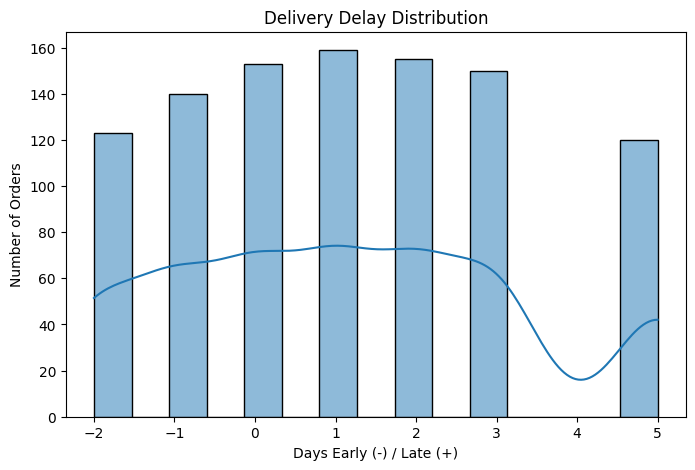


Final Purchase Dataset:


,Purchase_ID,Product_ID,Supplier_ID,Purchase_Date,Quantity,Unit_Cost,Expected_Delivery_Date,Actual_Delivery_Date,Status,Purchase_Amount,Delivery_Days,Month
0,PUR0001,PRD073,SUP018,2025-09-09,193,293.99,2025-09-13,2025-09-18,Delayed,56740.07,5,2025-09
1,PUR0002,PRD143,SUP016,2025-08-10,142,155.64,2025-08-16,2025-08-15,On Time,22100.88,-1,2025-08
2,PUR0003,PRD077,SUP002,2025-08-31,114,22.45,2025-09-06,2025-09-04,On Time,2559.30,-2,2025-08
3,PUR0004,PRD147,SUP017,2025-09-18,156,77.95,2025-09-24,2025-09-24,On Time,12160.20,0,2025-09
4,PUR0005,PRD119,SUP018,2025-03-18,64,71.68,2025-03-20,2025-03-18,On Time,4587.52,-2,2025-03
5,PUR0006,PRD097,SUP011,2025-10-11,101,281.23,2025-10-14,2025-10-17,Delayed,28404.23,3,2025-10
6,PUR0007,PRD112,SUP010,2025-09-07,24,131.55,2025-09-13,2025-09-18,Delayed,3157.20,5,2025-09
7,PUR0008,PRD181,SUP020,2025-04-18,154,284.83,2025-04-23,2025-04-26,Delayed,43863.82,3,2025-04
8,PUR0009,PRD136,SUP018,2025-06-25,78,259.28,2025-06-28,2025-07-01,Delayed,20223.84,3,2025-06
9,PUR0010,PRD197,SUP008,2025-10-27,37,140.73,2025-11-01,2025-11-01,On Time,5207.01,0,2025-10


In [ ]:
# ==========================================
# KIRANA STORE INTELLIGENCE
# PURCHASES DATA ANALYSIS
# ==========================================


# 1. Checking basic purchase information

print("Total Purchase Records:", purchases.shape[0])
print("Total Columns:", purchases.shape[1])

display(purchases.head())


# 2. Checking purchase summary

print("\nPurchase Summary:")
display(purchases.describe())


# 3. Calculating total purchase quantity and cost

purchases['Purchase_Amount'] = (
    purchases['Quantity'] * purchases['Unit_Cost']
)

print("\nTotal Purchase Quantity:", purchases['Quantity'].sum())

print("Total Purchase Amount:",
      round(purchases['Purchase_Amount'].sum(), 2))


# 4. Checking purchase status

print("\nPurchase Status:")
print(purchases['Status'].value_counts())


# 5. Analysing supplier-wise purchases

supplier_purchases = purchases.groupby('Supplier_ID').agg({
    'Purchase_ID': 'count',
    'Quantity': 'sum',
    'Purchase_Amount': 'sum'
}).rename(columns={
    'Purchase_ID': 'Total_Orders',
    'Quantity': 'Total_Quantity'
})

print("\nSupplier-wise Purchase Analysis:")
display(supplier_purchases.sort_values(
    by='Purchase_Amount', ascending=False
))


# 6. Analysing product-wise purchases

product_purchases = purchases.groupby('Product_ID').agg({
    'Quantity': 'sum',
    'Purchase_Amount': 'sum'
}).sort_values(by='Purchase_Amount', ascending=False)

print("\nTop 10 Purchased Products:")
display(product_purchases.head(10))


# 7. Checking delivery delays

purchases['Delivery_Days'] = (
    purchases['Actual_Delivery_Date'] -
    purchases['Expected_Delivery_Date']
).dt.days

print("\nDelivery Delay Summary:")
display(purchases['Delivery_Days'].describe())


# 8. Identifying delayed deliveries

delayed_purchases = purchases[
    purchases['Delivery_Days'] > 0
]

print("\nDelayed Purchases:")
display(delayed_purchases)


# 9. Calculating delivery performance

print("\nDelayed Orders:", len(delayed_purchases))

print("On-time or Early Orders:",
      (purchases['Delivery_Days'] <= 0).sum())


# 10. Monthly purchase analysis

purchases['Month'] = purchases['Purchase_Date'].dt.to_period('M')

monthly_purchases = purchases.groupby('Month').agg({
    'Purchase_Amount': 'sum',
    'Quantity': 'sum',
    'Purchase_ID': 'count'
}).rename(columns={'Purchase_ID': 'Total_Orders'})

print("\nMonthly Purchase Analysis:")
display(monthly_purchases)


# 11. Purchase amount by supplier chart

plt.figure(figsize=(10, 5))

supplier_purchases['Purchase_Amount'].sort_values(
    ascending=False
).head(10).plot(kind='bar')

plt.title('Top 10 Suppliers by Purchase Amount')
plt.xlabel('Supplier ID')
plt.ylabel('Purchase Amount')
plt.xticks(rotation=45)
plt.show()


# 12. Monthly purchase trend

plt.figure(figsize=(12, 5))

monthly_purchases['Purchase_Amount'].plot(
    kind='line', marker='o'
)

plt.title('Monthly Purchase Trend')
plt.xlabel('Month')
plt.ylabel('Purchase Amount')
plt.xticks(rotation=45)
plt.grid()
plt.show()


# 13. Delivery delay distribution

plt.figure(figsize=(8, 5))

sns.histplot(purchases['Delivery_Days'].dropna(), bins=15, kde=True)

plt.title('Delivery Delay Distribution')
plt.xlabel('Days Early (-) / Late (+)')
plt.ylabel('Number of Orders')
plt.show()


# 14. Final purchase analysis

print("\nFinal Purchase Dataset:")
display(purchases.head(10))

Total Suppliers: 20


,Supplier_ID,Supplier_Name,City,Supplier_Rating,Contact_Type
0,SUP001,Supplier_01,Mumbai,3.4,Manufacturer
1,SUP002,Supplier_02,Pune,4.8,Manufacturer
2,SUP003,Supplier_03,Pune,4.1,Wholesaler
3,SUP004,Supplier_04,Navi Mumbai,4.6,Manufacturer
4,SUP005,Supplier_05,Navi Mumbai,3.6,Wholesaler



Supplier Rating Distribution:
Supplier_Rating
3.4    2
4.1    2
4.6    2
4.4    2
3.6    1
3.1    1
3.9    1
4.8    1
2.7    1
4.9    1
4.7    1
3.0    1
3.7    1
2.6    1
2.9    1
4.2    1
Name: count, dtype: int64

Supplier Performance:


,Supplier_ID,Supplier_Name,City,Total_Orders,Total_Quantity,Total_Purchase_Amount,Average_Delivery_Days,Supplier_Rating
0,SUP001,Supplier_01,Mumbai,43,4194,709270.85,1.14,3.4
1,SUP002,Supplier_02,Pune,47,4898,791829.29,1.36,4.8
2,SUP003,Supplier_03,Pune,45,4942,813203.34,1.20,4.1
3,SUP004,Supplier_04,Navi Mumbai,59,6471,1112148.52,1.07,4.6
4,SUP005,Supplier_05,Navi Mumbai,45,5059,855232.97,1.67,3.6
5,SUP006,Supplier_06,Nashik,56,6141,934657.34,1.61,3.1
6,SUP007,Supplier_07,Mumbai,52,5670,874207.76,0.83,3.9
7,SUP008,Supplier_08,Pune,52,5716,937222.41,1.10,2.7
8,SUP009,Supplier_09,Thane,45,5804,807320.84,1.58,4.6
9,SUP010,Supplier_10,Mumbai,52,5625,832368.21,1.13,4.1



Top 10 Suppliers by Purchase Amount:


,Supplier_ID,Supplier_Name,City,Total_Orders,Total_Quantity,Total_Purchase_Amount,Average_Delivery_Days,Supplier_Rating
17,SUP018,Supplier_18,Mumbai,62,7005,1193598.14,1.048387,2.6
3,SUP004,Supplier_04,Navi Mumbai,59,6471,1112148.52,1.067797,4.6
12,SUP013,Supplier_13,Pune,59,6060,944648.52,1.152542,4.9
7,SUP008,Supplier_08,Pune,52,5716,937222.41,1.096154,2.7
5,SUP006,Supplier_06,Nashik,56,6141,934657.34,1.607143,3.1
11,SUP012,Supplier_12,Nashik,47,5802,880756.72,1.000000,3.4
6,SUP007,Supplier_07,Mumbai,52,5670,874207.76,0.826923,3.9
10,SUP011,Supplier_11,Navi Mumbai,56,5488,861557.78,1.339286,4.4
4,SUP005,Supplier_05,Navi Mumbai,45,5059,855232.97,1.666667,3.6
9,SUP010,Supplier_10,Mumbai,52,5625,832368.21,1.134615,4.1



Highest Rated Suppliers:


,Supplier_ID,Supplier_Name,City,Total_Orders,Total_Quantity,Total_Purchase_Amount,Average_Delivery_Days,Supplier_Rating
12,SUP013,Supplier_13,Pune,59,6060,944648.52,1.152542,4.9
1,SUP002,Supplier_02,Pune,47,4898,791829.29,1.361702,4.8
13,SUP014,Supplier_14,Pune,49,5059,800582.36,0.775510,4.7
3,SUP004,Supplier_04,Navi Mumbai,59,6471,1112148.52,1.067797,4.6
8,SUP009,Supplier_09,Thane,45,5804,807320.84,1.577778,4.6
10,SUP011,Supplier_11,Navi Mumbai,56,5488,861557.78,1.339286,4.4
14,SUP015,Supplier_15,Pune,40,4442,707477.85,0.550000,4.4
19,SUP020,Supplier_20,Navi Mumbai,49,5182,796531.37,1.000000,4.2
9,SUP010,Supplier_10,Mumbai,52,5625,832368.21,1.134615,4.1
2,SUP003,Supplier_03,Pune,45,4942,813203.34,1.200000,4.1



Suppliers by City:
City
Pune           7
Navi Mumbai    5
Mumbai         4
Nashik         3
Thane          1
Name: count, dtype: int64

Supplier Contact Types:
Contact_Type
Manufacturer    7
Wholesaler      7
Distributor     6
Name: count, dtype: int64


<Figure size 1000x500 with 0 Axes>

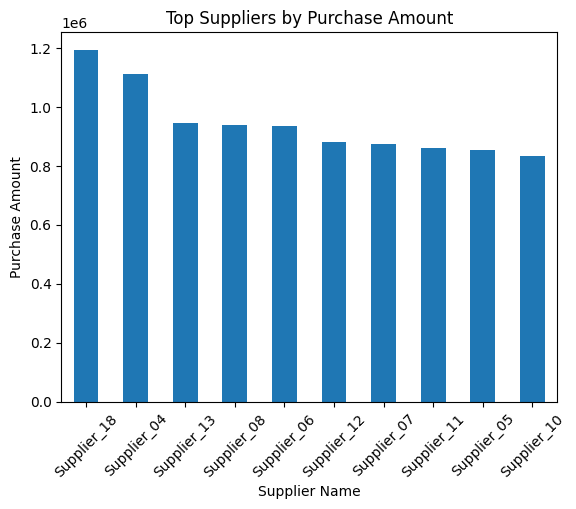

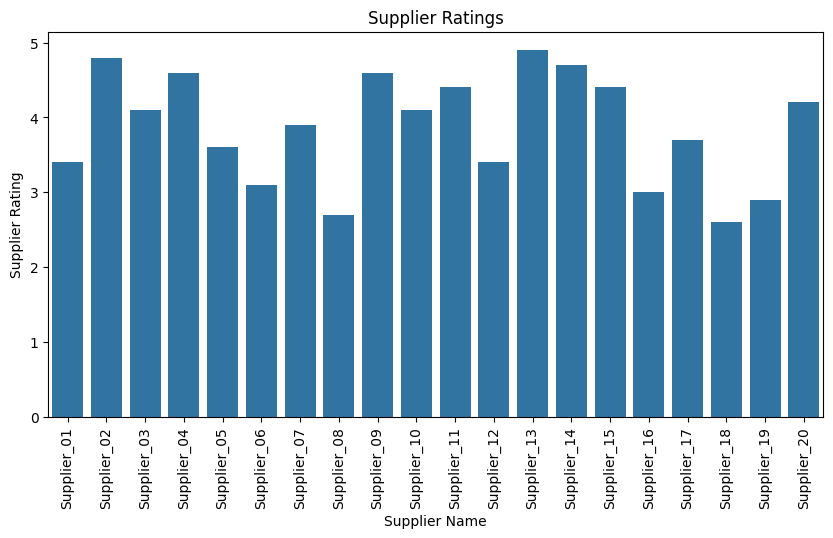

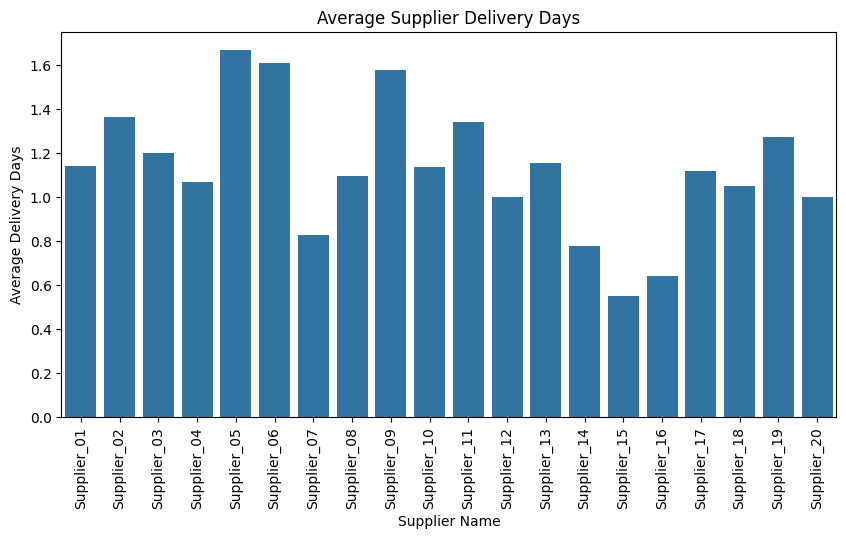


Final Supplier Performance:


,Supplier_ID,Supplier_Name,City,Total_Orders,Total_Quantity,Total_Purchase_Amount,Average_Delivery_Days,Supplier_Rating
0,SUP001,Supplier_01,Mumbai,43,4194,709270.85,1.14,3.4
1,SUP002,Supplier_02,Pune,47,4898,791829.29,1.36,4.8
2,SUP003,Supplier_03,Pune,45,4942,813203.34,1.20,4.1
3,SUP004,Supplier_04,Navi Mumbai,59,6471,1112148.52,1.07,4.6
4,SUP005,Supplier_05,Navi Mumbai,45,5059,855232.97,1.67,3.6
5,SUP006,Supplier_06,Nashik,56,6141,934657.34,1.61,3.1
6,SUP007,Supplier_07,Mumbai,52,5670,874207.76,0.83,3.9
7,SUP008,Supplier_08,Pune,52,5716,937222.41,1.10,2.7
8,SUP009,Supplier_09,Thane,45,5804,807320.84,1.58,4.6
9,SUP010,Supplier_10,Mumbai,52,5625,832368.21,1.13,4.1


In [ ]:
# ==========================================
# KIRANA STORE INTELLIGENCE
# SUPPLIER PERFORMANCE ANALYSIS
# ==========================================


# 1. Checking supplier information

print("Total Suppliers:", suppliers.shape[0])

display(suppliers.head())


# 2. Checking supplier ratings

print("\nSupplier Rating Distribution:")
print(suppliers['Supplier_Rating'].value_counts())


# 3. Merging suppliers with purchase records

supplier_analysis = pd.merge(
    purchases,
    suppliers,
    on='Supplier_ID',
    how='left'
)


# 4. Calculating supplier-wise performance

supplier_performance = supplier_analysis.groupby(
    ['Supplier_ID', 'Supplier_Name', 'City']
).agg({
    'Purchase_ID': 'count',
    'Quantity': 'sum',
    'Purchase_Amount': 'sum',
    'Delivery_Days': 'mean',
    'Supplier_Rating': 'mean'
}).reset_index()


# 5. Renaming columns

supplier_performance.rename(columns={
    'Purchase_ID': 'Total_Orders',
    'Quantity': 'Total_Quantity',
    'Purchase_Amount': 'Total_Purchase_Amount',
    'Delivery_Days': 'Average_Delivery_Days'
}, inplace=True)


# 6. Displaying supplier performance

print("\nSupplier Performance:")

display(supplier_performance.round(2))


# 7. Identifying top suppliers by purchase amount

print("\nTop 10 Suppliers by Purchase Amount:")

display(
    supplier_performance.nlargest(
        10, 'Total_Purchase_Amount'
    )
)


# 8. Identifying highest-rated suppliers

print("\nHighest Rated Suppliers:")

display(
    supplier_performance.sort_values(
        by='Supplier_Rating',
        ascending=False
    ).head(10)
)


# 9. Analysing supplier city distribution

print("\nSuppliers by City:")

print(suppliers['City'].value_counts())


# 10. Analysing supplier contact types

print("\nSupplier Contact Types:")

print(suppliers['Contact_Type'].value_counts())


# 11. Supplier purchase amount chart

plt.figure(figsize=(10, 5))

supplier_performance.nlargest(
    10, 'Total_Purchase_Amount'
).plot(
    x='Supplier_Name',
    y='Total_Purchase_Amount',
    kind='bar',
    legend=False
)

plt.title('Top Suppliers by Purchase Amount')
plt.xlabel('Supplier Name')
plt.ylabel('Purchase Amount')
plt.xticks(rotation=45)
plt.show()


# 12. Supplier rating chart

plt.figure(figsize=(10, 5))

sns.barplot(
    data=supplier_performance,
    x='Supplier_Name',
    y='Supplier_Rating',
    errorbar=None
)

plt.title('Supplier Ratings')
plt.xlabel('Supplier Name')
plt.ylabel('Supplier Rating')
plt.xticks(rotation=90)
plt.show()


# 13. Supplier delivery performance

plt.figure(figsize=(10, 5))

sns.barplot(
    data=supplier_performance,
    x='Supplier_Name',
    y='Average_Delivery_Days',
    errorbar=None
)

plt.title('Average Supplier Delivery Days')
plt.xlabel('Supplier Name')
plt.ylabel('Average Delivery Days')
plt.xticks(rotation=90)
plt.show()


# 14. Final supplier performance dataset

print("\nFinal Supplier Performance:")

display(supplier_performance.round(2))

Total Expiry Records: 500


,Batch_ID,Product_ID,Received_Date,Expiry_Date,Batch_Quantity
0,BAT0001,PRD073,2025-11-16,2025-11-23,35
1,BAT0002,PRD181,2025-10-08,2026-01-06,96
2,BAT0003,PRD046,2025-10-07,2025-10-14,26
3,BAT0004,PRD118,2025-11-18,2026-02-16,38
4,BAT0005,PRD043,2025-11-30,2025-12-15,89


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Batch_ID        500 non-null    object        
 1   Product_ID      500 non-null    object        
 2   Received_Date   500 non-null    datetime64[ns]
 3   Expiry_Date     500 non-null    datetime64[ns]
 4   Batch_Quantity  500 non-null    int64         
dtypes: datetime64[ns](2), int64(1), object(2)
memory usage: 19.7+ KB

Missing Values:
Batch_ID          0
Product_ID        0
Received_Date     0
Expiry_Date       0
Batch_Quantity    0
dtype: int64

Expiry Date Range:
Earliest Expiry: 2025-10-09 00:00:00
Latest Expiry: 2026-12-14 00:00:00

Expiry Status Distribution:
Expiry_Status
Expired          479
Expiring Soon     21
Name: count, dtype: int64

Expired Batches:


,Batch_ID,Product_ID,Received_Date,Expiry_Date,Batch_Quantity,Days_To_Expiry,Expiry_Status
0,BAT0001,PRD073,2025-11-16,2025-11-23,35,-366,Expired
1,BAT0002,PRD181,2025-10-08,2026-01-06,96,-322,Expired
2,BAT0003,PRD046,2025-10-07,2025-10-14,26,-406,Expired
3,BAT0004,PRD118,2025-11-18,2026-02-16,38,-281,Expired
4,BAT0005,PRD043,2025-11-30,2025-12-15,89,-344,Expired
...,...,...,...,...,...,...,...
495,BAT0496,PRD076,2025-11-17,2026-05-16,12,-192,Expired
496,BAT0497,PRD049,2025-12-14,2026-06-12,30,-165,Expired
497,BAT0498,PRD044,2025-10-07,2026-04-05,87,-233,Expired
498,BAT0499,PRD014,2025-11-11,2026-01-10,5,-318,Expired



Near Expiry Batches:


,Batch_ID,Product_ID,Received_Date,Expiry_Date,Batch_Quantity,Days_To_Expiry,Expiry_Status
27,BAT0028,PRD063,2025-12-05,2026-12-05,21,11,Expiring Soon
52,BAT0053,PRD076,2025-11-30,2026-11-30,47,6,Expiring Soon
59,BAT0060,PRD128,2025-12-14,2026-12-14,22,20,Expiring Soon
63,BAT0064,PRD020,2025-11-28,2026-11-28,26,4,Expiring Soon
69,BAT0070,PRD033,2025-12-09,2026-12-09,92,15,Expiring Soon
96,BAT0097,PRD136,2025-12-01,2026-12-01,71,7,Expiring Soon
103,BAT0104,PRD131,2025-12-13,2026-12-13,9,19,Expiring Soon
107,BAT0108,PRD189,2025-11-26,2026-11-26,81,2,Expiring Soon
158,BAT0159,PRD064,2025-12-07,2026-12-07,51,13,Expiring Soon
163,BAT0164,PRD170,2025-11-25,2026-11-25,26,1,Expiring Soon



Expired Quantity: 25863
Near Expiry Quantity: 936

Expired Stock Cost Value: 3787952.9
Near Expiry Stock Cost Value: 144828.23

Category-wise Expiry Analysis:


,Batch_Quantity,Batch_Cost_Value
Category,,
Beverages,5701,755956.23
Dairy,6253,934721.91
Personal Care,4705,638853.80
Snacks,5637,798767.10
Staples,4503,804482.09


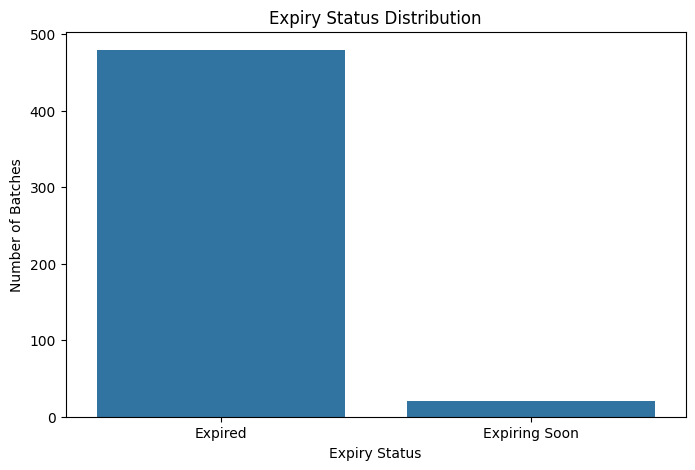

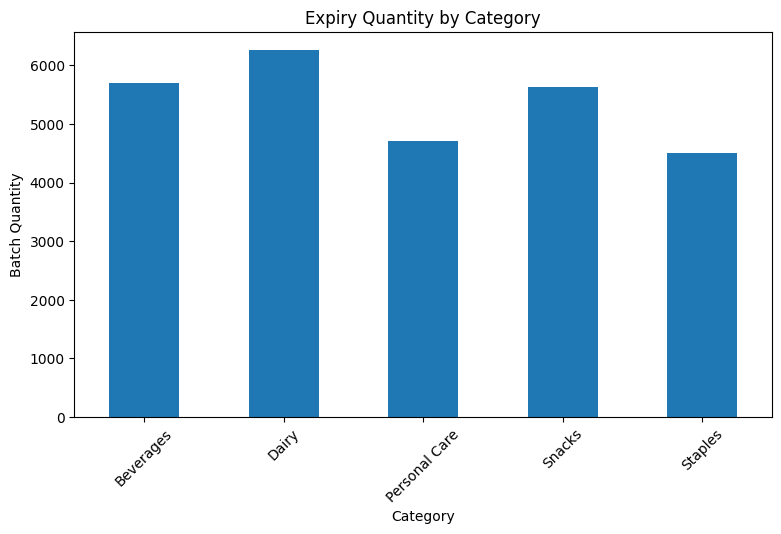


Final Expiry Analysis:


,Batch_ID,Product_ID,Received_Date,Expiry_Date,Batch_Quantity,Days_To_Expiry,Expiry_Status,Product_Name,Category,Supplier_ID,Cost_Price,Selling_Price,Shelf_Life_Days,Profit,Profit_Margin,Batch_Cost_Value
393,BAT0394,PRD052,2025-10-02,2025-10-09,23,-411,Expired,Cheese_052,Dairy,SUP008,281.97,373.84,7,91.87,24.574684,6485.31
17,BAT0018,PRD080,2025-10-02,2025-10-09,69,-411,Expired,Shampoo_080,Personal Care,SUP019,66.97,82.49,90,15.52,18.814402,4620.93
389,BAT0390,PRD167,2025-10-06,2025-10-13,42,-407,Expired,Lotion_167,Personal Care,SUP001,115.62,142.58,7,26.96,18.908683,4856.04
82,BAT0083,PRD078,2025-10-07,2025-10-14,68,-406,Expired,Cheese_078,Dairy,SUP003,54.45,64.50,90,10.05,15.581395,3702.60
2,BAT0003,PRD046,2025-10-07,2025-10-14,26,-406,Expired,Curd_046,Dairy,SUP003,59.47,86.41,365,26.94,31.176947,1546.22
467,BAT0468,PRD069,2025-10-08,2025-10-15,75,-405,Expired,Biscuits_069,Snacks,SUP014,136.18,201.17,60,64.99,32.306010,10213.50
110,BAT0111,PRD017,2025-10-09,2025-10-16,75,-404,Expired,Chips_017,Snacks,SUP013,257.49,310.07,30,52.58,16.957461,19311.75
482,BAT0483,PRD124,2025-10-01,2025-10-16,74,-404,Expired,Lotion_124,Personal Care,SUP007,24.28,30.46,30,6.18,20.288903,1796.72
329,BAT0330,PRD070,2025-10-09,2025-10-16,6,-404,Expired,Wheat Flour_070,Staples,SUP013,268.59,373.21,7,104.62,28.032475,1611.54
38,BAT0039,PRD152,2025-10-10,2025-10-17,60,-403,Expired,Soft Drinks_152,Beverages,SUP009,242.26,323.11,30,80.85,25.022438,14535.60


In [ ]:
# ==========================================
# KIRANA STORE INTELLIGENCE
# EXPIRY DATA ANALYSIS
# ==========================================


# 1. Checking expiry dataset

print("Total Expiry Records:", expiry.shape[0])

display(expiry.head())


# 2. Checking expiry dataset information

expiry.info()


# 3. Checking missing values

print("\nMissing Values:")
print(expiry.isnull().sum())


# 4. Checking expiry date range

print("\nExpiry Date Range:")
print("Earliest Expiry:", expiry['Expiry_Date'].min())
print("Latest Expiry:", expiry['Expiry_Date'].max())


# 5. Calculating remaining shelf life

expiry['Days_To_Expiry'] = (
    expiry['Expiry_Date'] - pd.Timestamp.today().normalize()
).dt.days


# 6. Categorising expiry status

expiry['Expiry_Status'] = np.select(
    [
        expiry['Days_To_Expiry'] < 0,
        expiry['Days_To_Expiry'] <= 30
    ],
    [
        'Expired',
        'Expiring Soon'
    ],
    default='Safe'
)


# 7. Checking expiry status count

print("\nExpiry Status Distribution:")
print(expiry['Expiry_Status'].value_counts())


# 8. Identifying expired batches

expired_batches = expiry[
    expiry['Expiry_Status'] == 'Expired'
]

print("\nExpired Batches:")
display(expired_batches)


# 9. Identifying products expiring within 30 days

near_expiry = expiry[
    expiry['Expiry_Status'] == 'Expiring Soon'
]

print("\nNear Expiry Batches:")
display(near_expiry)


# 10. Calculating total quantity at expiry risk

print("\nExpired Quantity:",
      expired_batches['Batch_Quantity'].sum())

print("Near Expiry Quantity:",
      near_expiry['Batch_Quantity'].sum())


# 11. Merging expiry data with products

expiry_analysis = pd.merge(
    expiry,
    products,
    on='Product_ID',
    how='left'
)


# 12. Calculating potential inventory cost

expiry_analysis['Batch_Cost_Value'] = (
    expiry_analysis['Batch_Quantity'] *
    expiry_analysis['Cost_Price']
)


# 13. Calculating expired stock value

expired_value = expiry_analysis.loc[
    expiry_analysis['Expiry_Status'] == 'Expired',
    'Batch_Cost_Value'
].sum()

print("\nExpired Stock Cost Value:", round(expired_value, 2))


# 14. Calculating near-expiry stock value

near_expiry_value = expiry_analysis.loc[
    expiry_analysis['Expiry_Status'] == 'Expiring Soon',
    'Batch_Cost_Value'
].sum()

print("Near Expiry Stock Cost Value:",
      round(near_expiry_value, 2))


# 15. Category-wise expiry analysis

print("\nCategory-wise Expiry Analysis:")

category_expiry = expiry_analysis.groupby('Category').agg({
    'Batch_Quantity': 'sum',
    'Batch_Cost_Value': 'sum'
})

display(category_expiry.round(2))


# 16. Expiry status visualisation

plt.figure(figsize=(8, 5))

sns.countplot(data=expiry, x='Expiry_Status')

plt.title('Expiry Status Distribution')
plt.xlabel('Expiry Status')
plt.ylabel('Number of Batches')
plt.show()


# 17. Category-wise expiry quantity

plt.figure(figsize=(9, 5))

expiry_analysis.groupby('Category')['Batch_Quantity'].sum().plot(
    kind='bar'
)

plt.title('Expiry Quantity by Category')
plt.xlabel('Category')
plt.ylabel('Batch Quantity')
plt.xticks(rotation=45)
plt.show()


# 18. Final expiry analysis

print("\nFinal Expiry Analysis:")

display(
    expiry_analysis.sort_values(
        by='Days_To_Expiry'
    ).head(20)
)

In [ ]:
# ==========================================
# KIRANA STORE INTELLIGENCE
# COMBINED BUSINESS ANALYSIS
# ==========================================


# 1. Calculating overall business KPIs

total_revenue = sales['Revenue'].sum()
total_profit = sales['Profit'].sum()
total_cost = sales['Total_Cost'].sum()
total_units_sold = sales['Quantity'].sum()
total_transactions = sales['Sale_ID'].nunique()

print("========== BUSINESS KPIs ==========")

print("Total Revenue:", round(total_revenue, 2))
print("Total Profit:", round(total_profit, 2))
print("Total Cost:", round(total_cost, 2))
print("Total Units Sold:", total_units_sold)
print("Total Transactions:", total_transactions)

print("Overall Profit Margin:",
      round((total_profit / total_revenue) * 100, 2), "%")


# 2. Merging sales with product details

combined_sales = pd.merge(
    sales,
    products[['Product_ID', 'Product_Name', 'Category']],
    on='Product_ID',
    how='left'
)


# 3. Category-wise business performance

category_performance = combined_sales.groupby('Category').agg({
    'Revenue': 'sum',
    'Profit': 'sum',
    'Quantity': 'sum',
    'Sale_ID': 'count'
}).rename(columns={
    'Sale_ID': 'Total_Transactions'
})

print("\n========== CATEGORY PERFORMANCE ==========")

display(category_performance.sort_values(
    by='Revenue', ascending=False
).round(2))


# 4. Top 10 revenue-generating products

top_selling_products = combined_sales.groupby(
    ['Product_ID', 'Product_Name']
).agg({
    'Quantity': 'sum',
    'Revenue': 'sum',
    'Profit': 'sum'
}).sort_values(
    by='Revenue', ascending=False
).head(10)

print("\n========== TOP 10 PRODUCTS ==========")

display(top_selling_products.round(2))


# 5. Inventory risk analysis

print("\n========== INVENTORY ANALYSIS ==========")

# Merging inventory with products to compute inventory cost value
inventory_analysis = pd.merge(
    inventory,
    products[['Product_ID', 'Cost_Price']],
    on='Product_ID',
    how='left'
)
inventory_analysis['Inventory_Value'] = inventory_analysis['Stock_Quantity'] * inventory_analysis['Cost_Price']

print("Low Stock Products:",
      (inventory_analysis['Stock_Quantity'] < inventory_analysis['Reorder_Level']).sum())

print("Overstock Products:",
      (inventory_analysis['Stock_Quantity'] > inventory_analysis['Maximum_Stock']).sum())

print("Total Inventory Value:",
      round(inventory_analysis['Inventory_Value'].sum(), 2))


# 6. Purchase performance

print("\n========== PURCHASE ANALYSIS ==========")

print("Total Purchase Amount:",
      round(purchases['Purchase_Amount'].sum(), 2))

print("Total Purchase Orders:",
      purchases['Purchase_ID'].nunique())

print("Delayed Deliveries:",
      (purchases['Delivery_Days'] > 0).sum())


# 7. Supplier performance

print("\n========== SUPPLIER ANALYSIS ==========")

print("Total Suppliers:", suppliers['Supplier_ID'].nunique())

print("Average Supplier Rating:",
      round(suppliers['Supplier_Rating'].mean(), 2))

display(
    supplier_performance.nlargest(
        5, 'Total_Purchase_Amount'
    )
)


# 8. Expiry risk analysis

print("\n========== EXPIRY ANALYSIS ==========")

print("Expired Batches:", len(expired_batches))

print("Near Expiry Batches:", len(near_expiry))

print("Expired Stock Value:", round(expired_value, 2))

print("Near Expiry Stock Value:", round(near_expiry_value, 2))


# 9. Monthly revenue and profit

print("\n========== MONTHLY PERFORMANCE ==========")

monthly_performance = sales.groupby(
    sales['Sale_Date'].dt.to_period('M')
).agg({
    'Revenue': 'sum',
    'Profit': 'sum',
    'Quantity': 'sum'
})

display(monthly_performance)


# 10. Final business summary

business_summary = pd.DataFrame({
    'Metric': [
        'Total Revenue',
        'Total Profit',
        'Total Cost',
        'Total Units Sold',
        'Total Transactions',
        'Total Products',
        'Total Suppliers',
        'Total Inventory Value',
        'Expired Stock Value',
        'Near Expiry Stock Value'
    ],
    'Value': [
        total_revenue,
        total_profit,
        total_cost,
        total_units_sold,
        total_transactions,
        products['Product_ID'].nunique(),
        suppliers['Supplier_ID'].nunique(),
        inventory_analysis['Inventory_Value'].sum(),
        expired_value,
        near_expiry_value
    ]
})

print("\n========== FINAL BUSINESS SUMMARY ==========")

display(business_summary.round(2))

========== BUSINESS KPIs ==========
Total Revenue: 9862968.06
Total Profit: 1749824.69
Total Cost: 8113143.37
Total Units Sold: 55473
Total Transactions: 10000
Overall Profit Margin: 17.74 %

========== CATEGORY PERFORMANCE ==========


,Revenue,Profit,Quantity,Total_Transactions
Category,,,,
Dairy,2262803.89,443902.87,11288,2032
Snacks,2209721.49,379568.10,12704,2320
Beverages,1857078.99,321938.46,11055,2011
Personal Care,1801015.87,304159.96,11250,2017
Staples,1732347.82,300255.30,9176,1620



========== TOP 10 PRODUCTS ==========


,,Quantity,Revenue,Profit
Product_ID,Product_Name,,,
PRD003,Soap_003,397,130347.66,30557.74
PRD129,Pulses_129,326,125236.83,29366.75
PRD141,Shampoo_141,371,123408.85,21109.31
PRD070,Wheat Flour_070,342,119651.12,27793.34
PRD008,Cheese_008,402,110264.40,24035.40
PRD196,Soft Drinks_196,302,109737.95,25461.83
PRD128,Water_128,312,108781.48,29333.80
PRD159,Paneer_159,354,107922.05,25956.89
PRD073,Detergent_073,352,103985.98,21660.22



========== INVENTORY ANALYSIS ==========
Low Stock Products: 30
Overstock Products: 47
Total Inventory Value: 4246604.7

========== PURCHASE ANALYSIS ==========
Total Purchase Amount: 17039969.57
Total Purchase Orders: 1000
Delayed Deliveries: 584

========== SUPPLIER ANALYSIS ==========
Total Suppliers: 20
Average Supplier Rating: 3.86


,Supplier_ID,Supplier_Name,City,Total_Orders,Total_Quantity,Total_Purchase_Amount,Average_Delivery_Days,Supplier_Rating
17,SUP018,Supplier_18,Mumbai,62,7005,1193598.14,1.048387,2.6
3,SUP004,Supplier_04,Navi Mumbai,59,6471,1112148.52,1.067797,4.6
12,SUP013,Supplier_13,Pune,59,6060,944648.52,1.152542,4.9
7,SUP008,Supplier_08,Pune,52,5716,937222.41,1.096154,2.7
5,SUP006,Supplier_06,Nashik,56,6141,934657.34,1.607143,3.1



========== EXPIRY ANALYSIS ==========
Expired Batches: 479
Near Expiry Batches: 21
Expired Stock Value: 3787952.9
Near Expiry Stock Value: 144828.23

========== MONTHLY PERFORMANCE ==========


,Revenue,Profit,Quantity
Sale_Date,,,
2025-01,748760.22,131012.29,4461
2025-02,795050.20,143104.82,4391
2025-03,838191.75,140868.38,4817
2025-04,840337.63,152182.04,4716
2025-05,802151.04,146270.42,4662
2025-06,888735.69,161957.10,4779
2025-07,844502.10,151964.32,4817
2025-08,864733.89,152721.97,4737
2025-09,757172.82,134435.86,4313



========== FINAL BUSINESS SUMMARY ==========


,Metric,Value
0,Total Revenue,9862968.06
1,Total Profit,1749824.69
2,Total Cost,8113143.37
3,Total Units Sold,55473.00
4,Total Transactions,10000.00
5,Total Products,200.00
6,Total Suppliers,20.00
7,Total Inventory Value,4246604.70
8,Expired Stock Value,3787952.90
9,Near Expiry Stock Value,144828.23
